# 03. Recovery study

Repeated datasets of 50,000 chats from the `baseline` preset. Each estimator is
fitted to each dataset. The truth comes from one million simulated chats per
regime. Regenerate with:

```bash
uv run python tools/recovery.py --preset baseline --reps 20
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve() / "tools"))
from recovery import summarise

pd.set_option("display.width", 120)

In [2]:
import matplotlib.pyplot as plt

# Reference categorical palette, fixed order. Truth is drawn in ink.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
})

In [3]:
files = sorted(Path("../results").glob("recovery_baseline_*.csv"))
full = summarise(files, Path("../results/truth_baseline.csv"))
summary = full.xs(50_000, level="n_chats")
print(summary["reps"].groupby("estimator").max().to_string())
(summary[["rd_true", "rd_mean", "bias", "sd", "rmse"]] * 1000).round(2)

estimator
count_all                 10
count_window              10
count_window_sentiment    10
gformula                  10
ice                       20
ipw                       20
ltmle                     20
pooled_hazard             10


rd_true  rd_mean  bias    sd  rmse
estimator     regime                                                    
count_all     never_any                 -5.69   -10.24 -4.55  0.55  4.57
              never_escalation          -4.09    -8.90 -4.81  0.49  4.83
              never_requeue             -3.09    -0.61  2.48  0.30  2.50
              never_shift_change        -1.32    -0.07  1.26  0.31  1.29
              never_transfer            -0.45    -2.06 -1.61  0.47  1.67
...                                       ...      ...   ...   ...   ...
pooled_hazard scale_any_0.5             -3.21    -1.49  1.72  0.40  1.76
              scale_escalation_0.5      -1.89    -0.71  1.18  0.20  1.19
              scale_requeue_0.5         -1.66    -0.28  1.38  0.17  1.39
              scale_shift_change_0.5    -0.30    -0.11  0.20  0.14  0.24
              scale_transfer_0.5        -0.12    -0.43 -0.30  0.23  0.37

[80 rows x 5 columns]

Root mean squared error per 1,000 chats, by estimator and regime.

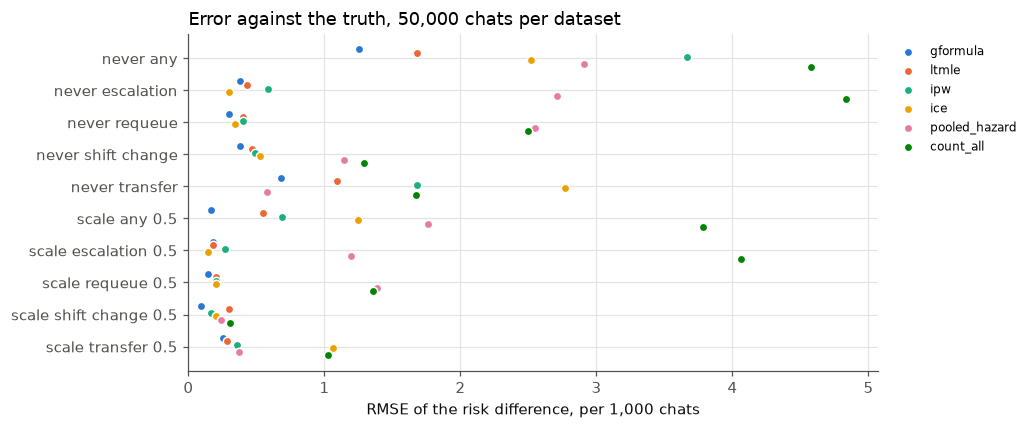

In [4]:
rmse = (summary["rmse"] * 1000).unstack("estimator")
# Six estimators keep the categorical palette within its validated range.
shown_est = ["ltmle", "gformula", "ipw", "ice", "pooled_hazard", "count_all"]
order = rmse[shown_est].mean().sort_values().index
rmse = rmse[order]
fig, ax = plt.subplots(figsize=(9.5, 4))
y = np.arange(len(rmse.index))
step = 0.11
for j, name in enumerate(order):
    off = (j - (len(order) - 1) / 2) * step
    ax.scatter(rmse[name], y + off, s=30, color=SERIES[j], label=name,
               edgecolor="white", linewidth=1, zorder=3)
ax.set_yticks(y, [s.replace("_", " ") for s in rmse.index])
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("RMSE of the risk difference, per 1,000 chats")
ax.set_title("Error against the truth, 50,000 chats per dataset", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

Relative bias: the mean estimate as a share of the true effect. 100% means
unbiased on average.

In [5]:
rel = (summary["rd_mean"] / summary["rd_true"] * 100).unstack("estimator")
rel.round(0)

estimator,count_all,count_window,count_window_sentiment,gformula,ice,ipw,ltmle,pooled_hazard
regime,,,,,,,,
never_any,180.0,120.0,122.0,86.0,143.0,114.0,116.0,50.0
never_escalation,218.0,80.0,82.0,93.0,100.0,109.0,100.0,34.0
never_requeue,20.0,64.0,64.0,96.0,95.0,99.0,96.0,18.0
never_shift_change,5.0,23.0,25.0,79.0,68.0,73.0,82.0,16.0
never_transfer,458.0,598.0,612.0,146.0,706.0,222.0,156.0,187.0
scale_any_0.5,217.0,131.0,134.0,98.0,137.0,117.0,105.0,46.0
scale_escalation_0.5,314.0,98.0,101.0,94.0,103.0,111.0,102.0,38.0
scale_requeue_0.5,19.0,67.0,68.0,95.0,96.0,99.0,96.0,17.0
scale_shift_change_0.5,13.0,54.0,57.0,85.0,135.0,136.0,127.0,35.0


Coverage of LTMLE's 95% influence-function intervals: the share of datasets
whose interval contains the true effect.

In [6]:
summary.xs("ltmle", level="estimator")[["coverage"]].round(2)

,coverage
regime,
never_any,0.85
never_escalation,0.90
never_requeue,0.90
never_shift_change,0.75
never_transfer,1.00
scale_any_0.5,1.00
scale_escalation_0.5,1.00
scale_requeue_0.5,0.90
scale_shift_change_0.5,0.95


## Larger samples

LTMLE and the g-formula at 200,000 chats. Bias that stays as the sample
grows comes from the method; bias that shrinks came from small samples.

In [7]:
sizes = sorted(full.index.get_level_values("n_chats").unique())
if len(sizes) > 1:
    keep = full.loc[full.index.get_level_values("estimator").isin(["gformula", "ltmle"])]
    out = (keep["rd_mean"] / keep["rd_true"] * 100).unstack("n_chats").round(0)
    out["rmse_ratio"] = (keep["rmse"].unstack("n_chats")[sizes[-1]]
                         / keep["rmse"].unstack("n_chats")[sizes[0]]).round(2)
    display(out)

n_chats                           50000  200000  rmse_ratio
estimator regime                                           
gformula  never_any                86.0    76.0        1.11
          never_escalation         93.0    90.0        1.23
          never_requeue            96.0   102.0        0.28
          never_shift_change       79.0    81.0        0.85
          never_transfer          146.0    47.0        0.45
          scale_any_0.5            98.0    93.0        1.73
          scale_escalation_0.5     94.0    88.0        1.44
          scale_requeue_0.5        95.0    97.0        0.44
          scale_shift_change_0.5   85.0    80.0        1.03
          scale_transfer_0.5      240.0    51.0        0.34
ltmle     never_any               116.0    99.0        0.28
          never_escalation        100.0    98.0        0.67
          never_requeue            96.0   101.0        0.34
          never_shift_change       82.0    89.0        0.53
          never_transfer          156.0   -58.0        0.67
          scale_any_0.5           105.0   104.0        0.26
          scale_escalation_0.5    102.0    97.0        0.56
          scale_requeue_0.5        96.0   103.0        0.34
          scale_shift_change_0.5  127.0   143.0        0.47
          scale_transfer_0.5      111.0    20.0        0.44